# Service 1 — Étape 3 : fine-tuning QLoRA de Qwen-2.5-7B-Instruct

**QLoRA** = le modèle de base est chargé **compressé en 4 bits** et **gelé** ; on entraîne seulement de petits
**adaptateurs LoRA** ajoutés à côté (environ 0,5 % des poids). Résultat : l'entraînement tient dans le GPU T4.

Suivi dans MLflow (expérience `cardioagent-llm`) : perte d'entraînement et perte de validation, réglages, adaptateur final.

**Avant de lancer :** GPU T4, puis *Exécution → Tout exécuter*. Durée estimée : 30 à 60 min.
Les points de sauvegarde vont sur le Drive : après une déconnexion, relancer reprend l'entraînement où il s'était arrêté.

## 1. Drive, code et chemins

In [1]:
import os
from google.colab import drive
drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive/cardioagent-ops"
REPO_URL = "https://github.com/yasssmine2003/CardioAgent-Ops.git"
REPO_DIR = "/content/CardioAgent-Ops"
if not os.path.isdir(REPO_DIR):
    !git clone -q {REPO_URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull -q
%cd {REPO_DIR}/llm_finetuning

CHECKPOINT_DIR = f"{DRIVE}/llm/checkpoints"          # points de sauvegarde (reprise après déconnexion)
ADAPTER_DIR = f"{DRIVE}/llm/adapter_qwen2.5-7b-cardio"  # adaptateur LoRA final
os.environ["MLFLOW_TRACKING_URI"] = f"file:{DRIVE}/mlruns"
os.environ["MLFLOW_EXPERIMENT_NAME"] = "cardioagent-llm"

Mounted at /content/drive
/content/CardioAgent-Ops/llm_finetuning


## 2. Installation

In [2]:
!pip install -q unsloth "mlflow>=2.17,<3"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires pyarrow>=23.0.1, but you have pyarrow 19.0.1 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


## 3. Réglages (tous nos choix [C], justifiés dans le journal)

| Réglage | Valeur | Rôle |
|---|---|---|
| `MAX_LENGTH` | 1024 tokens | Longueur maximale d'une conversation (les nôtres font moins de 700 tokens) |
| `LORA_R` | 16 | Taille des adaptateurs : plus grand = plus de capacité, mais plus de risque de sur-apprentissage |
| `LORA_ALPHA` | 16 | Force des adaptateurs (on prend alpha = r, la valeur habituelle) |
| `EPOCHS` | 2 | Nombre de passages sur les 931 conversations d'entraînement |
| `BATCH` × `ACCUM` | 2 × 4 = 8 | 8 conversations par mise à jour des poids |
| `LEARNING_RATE` | 2e-4 | Taille des pas d'apprentissage (valeur habituelle pour LoRA) |
| `VAL_RATIO` | 5 % | Part du train gardée pour la perte de validation (le test reste intact) |

In [3]:
MODEL_NAME = "unsloth/Qwen2.5-7B-Instruct-bnb-4bit"
MAX_LENGTH = 1024
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 16, 0.0
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
EPOCHS, BATCH, ACCUM = 2, 2, 4
LEARNING_RATE, WARMUP_STEPS, WEIGHT_DECAY = 2e-4, 10, 0.01
VAL_RATIO, EVAL_STEPS, SEED = 0.05, 20, 42

## 4. Modèle de base 4 bits + adaptateurs LoRA

In [4]:
import torch
from unsloth import FastLanguageModel

model, tokenizer = FastLanguageModel.from_pretrained(MODEL_NAME, max_seq_length=MAX_LENGTH, load_in_4bit=True)
model = FastLanguageModel.get_peft_model(
    model, r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, target_modules=LORA_TARGETS,
    bias="none", use_gradient_checkpointing="unsloth", random_state=SEED)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Paramètres entraînés : {trainable / 1e6:.1f} M sur {total / 1e6:.0f} M ({100 * trainable / total:.2f} %)")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1120 09:37:17.147000 674 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1120 09:37:17.186000 674 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.7: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Unsloth 2026.11.7 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
Paramètres entraînés : 40.4 M sur 4393 M (0.92 %)


## 5. Données : train / validation au format texte du modèle
Chaque conversation est transformée avec le *chat template* de Qwen (balises `<|im_start|>system`, `user`, `assistant`).
Le **test (109 conversations) n'est pas utilisé ici** : il sert seulement à l'étape 4.

In [5]:
from datasets import load_dataset

data = load_dataset("json", data_files="data/final/train.jsonl", split="train")
data = data.map(lambda e: {"text": tokenizer.apply_chat_template(e["messages"], tokenize=False)})
split = data.train_test_split(test_size=VAL_RATIO, seed=SEED)
train_ds, val_ds = split["train"], split["test"]

lengths = [len(tokenizer(t)["input_ids"]) for t in train_ds["text"]]
print(f"Train : {len(train_ds)} | validation : {len(val_ds)}")
print(f"Longueur en tokens : médiane {sorted(lengths)[len(lengths) // 2]}, max {max(lengths)} (limite {MAX_LENGTH})")
print("\nAperçu :\n", train_ds[0]["text"][:600])

Generating train split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/981 [00:00<?, ? examples/s]

Train : 931 | validation : 50
Longueur en tokens : médiane 384, max 496 (limite 1024)

Aperçu :
 <|im_start|>system
Tu es l'assistant médical de la plateforme CardioAgent, spécialisé en cardiologie et en auscultation cardiaque. Tu réponds de façon exacte et prudente, sans inventer d'information. Quand on te donne un résultat du moteur audio, tu réponds uniquement avec le JSON demandé. Sinon, tu réponds dans la langue de la question. Tu ne poses pas de diagnostic définitif et tu ne prescris pas de traitement.<|im_end|>
<|im_start|>user
A 60-year-old woman with a history of diabetes mellitus has had left-sided chest pain radiating to the arm for the past 5 hours. Serial measurements of seru


## 6. Entraîneur (TRL) — apprentissage sur les réponses seulement
`train_on_responses_only` : la perte n'est calculée **que sur la réponse de l'assistant**. Le modèle n'apprend pas à
réécrire la question ou la consigne, seulement à bien répondre.

On garde la **meilleure** version selon la perte de validation (comme le choix de la meilleure époque au Service 3).

In [6]:
import inspect
from trl import SFTConfig, SFTTrainer
from unsloth.chat_templates import train_on_responses_only

length_arg = "max_length" if "max_length" in inspect.signature(SFTConfig).parameters else "max_seq_length"
config = SFTConfig(
    output_dir=CHECKPOINT_DIR, dataset_text_field="text", **{length_arg: MAX_LENGTH},
    num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH, gradient_accumulation_steps=ACCUM,
    per_device_eval_batch_size=BATCH, learning_rate=LEARNING_RATE, warmup_steps=WARMUP_STEPS,
    weight_decay=WEIGHT_DECAY, lr_scheduler_type="linear", optim="adamw_8bit",
    fp16=not torch.cuda.is_bf16_supported(), bf16=torch.cuda.is_bf16_supported(),
    logging_steps=5, eval_strategy="steps", eval_steps=EVAL_STEPS,
    save_strategy="steps", save_steps=EVAL_STEPS, save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    report_to="mlflow", run_name="qlora_qwen2.5-7b", seed=SEED)

trainer = SFTTrainer(model=model, processing_class=tokenizer, train_dataset=train_ds, eval_dataset=val_ds, args=config)
trainer = train_on_responses_only(trainer, instruction_part="<|im_start|>user\n",
                                  response_part="<|im_start|>assistant\n")

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/931 [00:00<?, ? examples/s]

Unsloth: Packing train dataset (num_proc=2):   0%|          | 0/931 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/50 [00:00<?, ? examples/s]

Unsloth: Packing is on by default - documents are packed into full rows with no cross-document attention. Set packing = False in SFTConfig (or UNSLOTH_DEFAULT_PACKING=0) to turn it off.


Map:   0%|          | 0/354 [00:00<?, ? examples/s]

Map:   0%|          | 0/50 [00:00<?, ? examples/s]

## 7. Entraînement (reprend automatiquement après une déconnexion)

In [7]:
import glob, time
resume = bool(glob.glob(f"{CHECKPOINT_DIR}/checkpoint-*"))
print("Reprise depuis un point de sauvegarde" if resume else "Nouvel entraînement")
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
stats = trainer.train(resume_from_checkpoint=resume)
train_minutes = (time.perf_counter() - start) / 60
gpu_peak = torch.cuda.max_memory_allocated() / 1e9
print(f"Durée : {train_minutes:.0f} min | mémoire GPU max : {gpu_peak:.1f} Go | perte finale train : {stats.training_loss:.3f}")

Nouvel entraînement


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 354 | Num Epochs = 2 | Total steps = 90
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 40,370,176 of 7,655,986,688 (0.53% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
20,1.048510,1.159873
40,1.053508,1.037235


Filter:   0%|          | 0/50 [00:00<?, ? examples/s]

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cardioagent-ops/llm/checkpoints/checkpoint-20/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cardioagent-ops/llm/checkpoints/checkpoint-40/tokenizer_config.json.


Step,Training Loss,Validation Loss
20,1.048510,1.159873
40,1.053508,1.037235
60,0.916404,1.013914
80,0.884123,1.007354
90,0.698822,1.005645


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cardioagent-ops/llm/checkpoints/checkpoint-60/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cardioagent-ops/llm/checkpoints/checkpoint-80/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cardioagent-ops/llm/checkpoints/checkpoint-90/tokenizer_config.json.


Durée : 28 min | mémoire GPU max : 14.0 Go | perte finale train : 1.064


## 8. Courbe de perte (train / validation)

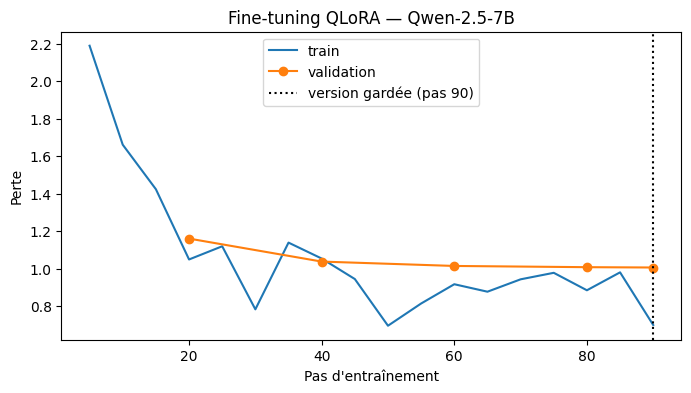

In [8]:
import matplotlib.pyplot as plt
log = trainer.state.log_history
train_pts = [(h["step"], h["loss"]) for h in log if "loss" in h]
val_pts = [(h["step"], h["eval_loss"]) for h in log if "eval_loss" in h]
best_step = int(trainer.state.best_model_checkpoint.split("-")[-1]) if trainer.state.best_model_checkpoint else None

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(*zip(*train_pts), label="train")
ax.plot(*zip(*val_pts), "o-", label="validation")
if best_step:
    ax.axvline(best_step, ls=":", color="black", label=f"version gardée (pas {best_step})")
ax.set(xlabel="Pas d'entraînement", ylabel="Perte", title="Fine-tuning QLoRA — Qwen-2.5-7B")
ax.legend()
fig.savefig("/content/loss_curve.png", dpi=130, bbox_inches="tight")
plt.show()

## 9. Sauvegarde de l'adaptateur + MLflow

In [9]:
import mlflow
model.save_pretrained(ADAPTER_DIR)           # adaptateur LoRA seulement (quelques dizaines de Mo)
tokenizer.save_pretrained(ADAPTER_DIR)

run_id = mlflow.last_active_run().info.run_id   # le run créé par l'entraîneur
with mlflow.start_run(run_id=run_id):
    mlflow.set_tags({"stage": "finetuning", "model": MODEL_NAME, "family": "training"})
    mlflow.log_params({"lora_r": LORA_R, "lora_alpha": LORA_ALPHA, "lora_targets": ",".join(LORA_TARGETS),
                       "max_length": MAX_LENGTH, "train_on_responses_only": True,
                       "n_train": len(train_ds), "n_val": len(val_ds)})
    mlflow.log_metrics({"train_minutes": train_minutes, "gpu_peak_gb": gpu_peak,
                        "trainable_params_m": trainable / 1e6, "best_eval_loss": trainer.state.best_metric})
    mlflow.log_artifact("/content/loss_curve.png")
    mlflow.log_artifacts(ADAPTER_DIR, artifact_path="adapter")
print("Adaptateur :", ADAPTER_DIR, "| run MLflow :", run_id)

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cardioagent-ops/llm/adapter_qwen2.5-7b-cardio/tokenizer_config.json.


Adaptateur : /content/drive/MyDrive/cardioagent-ops/llm/adapter_qwen2.5-7b-cardio | run MLflow : e7cb9fbb8cc3414da3564b052aa8af4e


## 10. Premier essai (une question Service 3 du test)

In [10]:
import json
FastLanguageModel.for_inference(model)
with open("data/final/test.jsonl", encoding="utf-8") as f:
    example = next(json.loads(l) for l in f if json.loads(l)["family"] == "service3")
inputs = tokenizer.apply_chat_template(example["messages"][:2], add_generation_prompt=True,
                                       return_tensors="pt", return_dict=True)
inputs = {k: v.to(model.device) for k, v in inputs.items()}
out = model.generate(**inputs, max_new_tokens=300, do_sample=False)
print(tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True))

Both `max_new_tokens` (=300) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{
  "resultat": "pathologique",
  "fiabilite": "élevée",
  "cas_limite": false,
  "interpretation": "Probabilité « pathologique » de 0,915, nettement au-dessus du seuil de décision (0,731). Analyse réalisée sur 6 segments de 5 s.",
  "recommandation": "Un avis cardiologique est recommandé pour confirmer ou écarter une anomalie.",
  "avertissement": "Outil d'aide au dépistage : il ne remplace pas un examen médical."
}
